In [7]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import xarray as xr 
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import json
import csv

In [8]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=int((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)


In [9]:
class data():
    def __init__(self,folder,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3):
        self.folder = folder
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.color=''
        self.BG=BG
        self.BG_ds=BG_ds
        self.g_err=g_err
        self.i_err=i_err
        self.footprint=footprint
        self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/'
        
    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/{self.period}_{self.BG_ds}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
        self.fluxes=self.fluxes.where((self.fluxes.time>=pd.to_datetime(self.start_date-dt.timedelta(days=6)))&(self.fluxes.time<=pd.to_datetime(self.end_date)),drop=True)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{self.path}/gosat_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.gosat=self.gosat.where((self.gosat.release_time>=pd.to_datetime(self.start_date))&(self.gosat.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.gosat=self.gosat.where((self.gosat.release_lat>analy_region_lat[0])&(self.gosat.release_lat<analy_region_lat[1])&(self.gosat.release_lon>analy_region_lon[0])&(self.gosat.release_lon<analy_region_lon[1]),drop=True)

    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{self.path}/insitu_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.insitu=self.insitu.where((self.insitu.release_time>=pd.to_datetime(self.start_date))&(self.insitu.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.insitu=self.insitu.where((self.insitu.release_lat>analy_region_lat[0])&(self.insitu.release_lat<analy_region_lat[1])&(self.insitu.release_lon>analy_region_lon[0])&(self.insitu.release_lon<analy_region_lon[1]),drop=True)
    def read_tccon(self):
        self.tccon=xr.open_dataset(f'{self.path}/TCCON_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.tccon=self.tccon.where((self.tccon.release_time>=pd.to_datetime(self.start_date))&(self.tccon.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.tccon=self.tccon.where((self.tccon.release_lat>analy_region_lat[0])&(self.tccon.release_lat<analy_region_lat[1])&(self.tccon.release_lon>analy_region_lon[0])&(self.tccon.release_lon<analy_region_lon[1]),drop=True)

    def read_data(self):
        self.read_fluxes()
        self.read_gosat()
        self.read_insitu()
        self.read_tccon()

In [10]:
def plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors,markers, title, start_date, end_date,spath):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dir in enumerate(datasets_dir):
        data[labels[k]]=xr.open_dataset(dir).sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'Total 2x2 flux, {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
            ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=labels[k])
            if parameters_uncertainty[k]!=False:
                ax[i].fill_between(data_sel.time, data_sel[parameters[k]]-data_sel[parameters_uncertainty[k]], data_sel[parameters[k]]+data_sel[parameters_uncertainty[k]], 
                               color=colors[k], alpha=0.2)        
        ax[i].legend()
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(-4e-7, 4e-7)
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [11]:
period='20201001-20220331'
analysis_start_date, analysis_end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
start_date, end_date =dt.date(2020,10,1), dt.date(2022,3,31)  
path='inversions_new/TM5_diurnal/'
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/diurnal/'

In [12]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')
TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(TM54DVar_posterior_flux.time<=pd.to_datetime(analysis_end_date)),drop=True)

In [13]:
prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_prior_cut_weekly.nc')
prior=prior.where((prior.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(prior.time<=pd.to_datetime(analysis_end_date)),drop=True)

In [14]:
nee_amplitude= data('inversions_new/TM5_correlations/',period,start_date, end_date,BG,BG_ds,correlation='with',g_err=2,i_err=3)
nee_amplitude.read_data()
nee2_amplitude=data(path+'TM5_2nee',period,start_date, end_date,BG,BG_ds,correlation='with',g_err=2,i_err=3)
nee2_amplitude.read_data()
nee05_amplitude=data(path+'TM5_05nee',period,start_date, end_date,BG,BG_ds,correlation='with',g_err=2,i_err=3)
nee05_amplitude.read_data()
scaled=data(path+'scaled',period,start_date, end_date,BG,BG_ds,footprint='spec001_mr_scaled',correlation='with',g_err=2,i_err=3)
scaled.read_data()
no_diurnal= data(path+'no_diurnal',period,start_date, end_date,BG,BG_ds,correlation='with',g_err=2,i_err=3)
no_diurnal.read_data()


# diurnal implementation/setup

/tmp/ipykernel_2148876/898997732.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_2148876/898997732.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_2148876/898997732.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


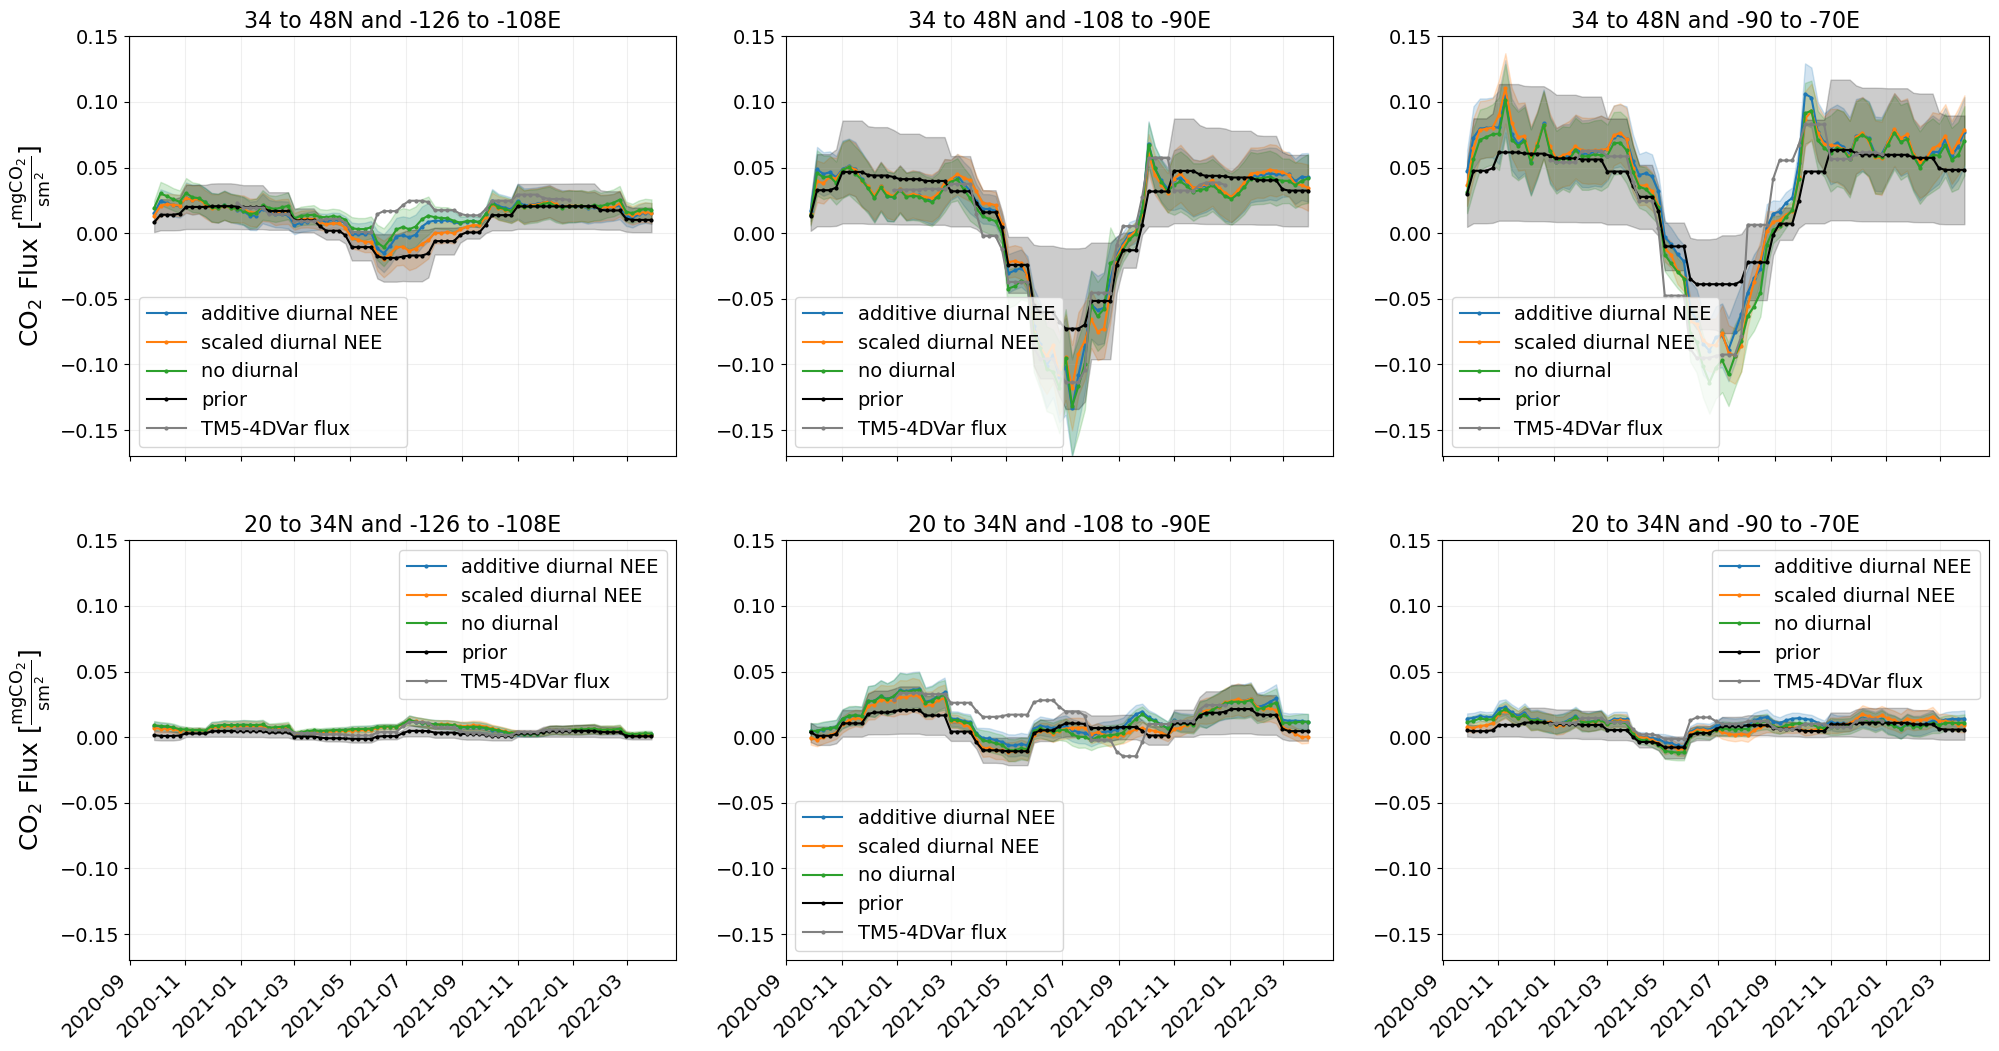

In [9]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['additive diurnal NEE','scaled diurnal NEE','no diurnal' ]                           # ['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.','NEE scaled', 'no diurnal']
datasets= [nee_amplitude, scaled,no_diurnal ]                                  # [nee_amplitude,nee2_amplitude,nee05_amplitude,scaled, no_diurnal]
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        k=0
        for k,data in enumerate(datasets):
            temp=data.fluxes
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{label_set[k]}')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6

        axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2)  
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')

        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(-0.17,0.15)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.savefig(f'{savefig}/regional_fluxes_diff_diurnal_setup.pdf',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

In [12]:
prior_path=f'{nee_amplitude.path}/{period}_{BG_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['additive diurnal NEE','scaled diurnal NEE','no diurnal']

colors=['black','grey']
marker=['x','x']
k=0
for k,dataset in enumerate([nee_amplitude,scaled,no_diurnal]):
    datasets_dir.append(f'{dataset.path}/{dataset.period}_{dataset.BG_ds}_bg.nc')
    labels.append(label_set[k])
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')
print(datasets_dir)
print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'different diurnal setups', analysis_start_date, analysis_end_date,savefig+'/different_diurnal_setup_'+'2x2.png')


['inversions_new/TM5_correlations//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', '/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc', 'inversions_new/TM5_correlations//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', 'inversions_new/TM5_diurnal/scaled/2x2/with_correlation/footprint_spec001_mr_scaled/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', 'inversions_new/TM5_diurnal/no_diurnal/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc']
['TM5_prior_flux', 'total_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux']
['prior_uncertainty', False, 'TM5_posterior_std', 'TM5_posterior_std', 'TM5

<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:30: SyntaxWarning: invalid escape sequence '\o'
<>:30: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\o'
<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:30: SyntaxWarning: invalid escape sequence '\o'
<>:30: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\o'
<>:43: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_758705/3818172821.py:18: SyntaxWarning: invalid escape sequence '\o'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_758705/3818172821.py:18: SyntaxWarning: invalid escape sequence '\s'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_758705/3818172821.py:30: SyntaxWarning: invalid escape sequence '\o'
  print(f'GOSA

NEE ampl.
insitu: , $\overline{d}=0.07, \sigma=2.82$
GOSAT: , $\overline{d}=0.05, \sigma=2.53$
TCCON: , $\overline{d}=-0.7, \sigma=1.89$
NEE scaled
insitu: , $\overline{d}=-0.29, \sigma=2.41$
GOSAT: , $\overline{d}=-0.05, \sigma=2.51$
TCCON: , $\overline{d}=-0.74, \sigma=1.91$
no diurnal
insitu: , $\overline{d}=-0.13, \sigma=2.84$
GOSAT: , $\overline{d}=0.09, \sigma=2.54$
TCCON: , $\overline{d}=-0.71, \sigma=1.87$


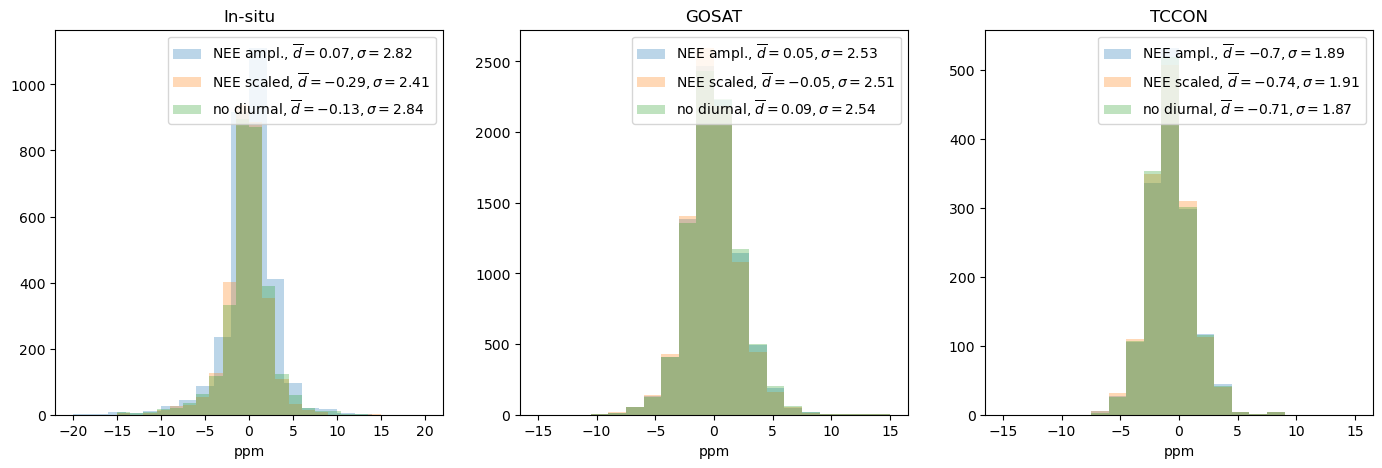

In [10]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
label_set=['NEE ampl.','NEE scaled','no diurnal']
for k,data in enumerate([nee_amplitude,scaled,no_diurnal]):
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    print(label_set[k])
    temp=data.insitu
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[0].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[0].legend()
    axs[0].set_xlabel('ppm')
    axs[0].set_title(title[0])

    max_min=(-15,15)
    temp=data.gosat
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'GOSAT: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[1].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[1].legend()
    axs[1].set_xlabel('ppm')
    axs[1].set_title(title[1])

    
    max_min=(-15,15)
    temp=data.tccon
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[2].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[2].legend()
    axs[2].set_xlabel('ppm')
    axs[2].set_title(title[2])

plt.savefig(f'{savefig}/histogramm_diff_diurnal.png')

<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2375853/4034925700.py:33: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
/tmp/ipykernel_2375853/4034925700.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


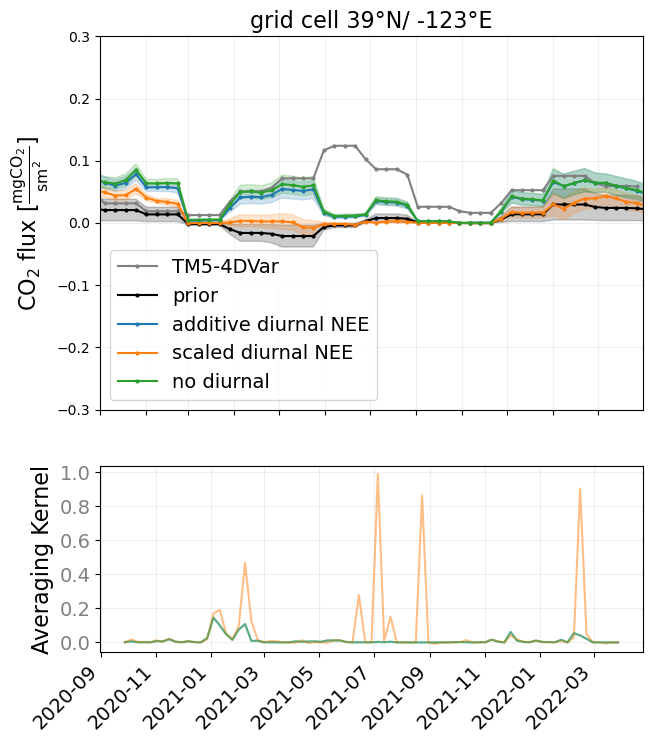

/tmp/ipykernel_2375853/4034925700.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


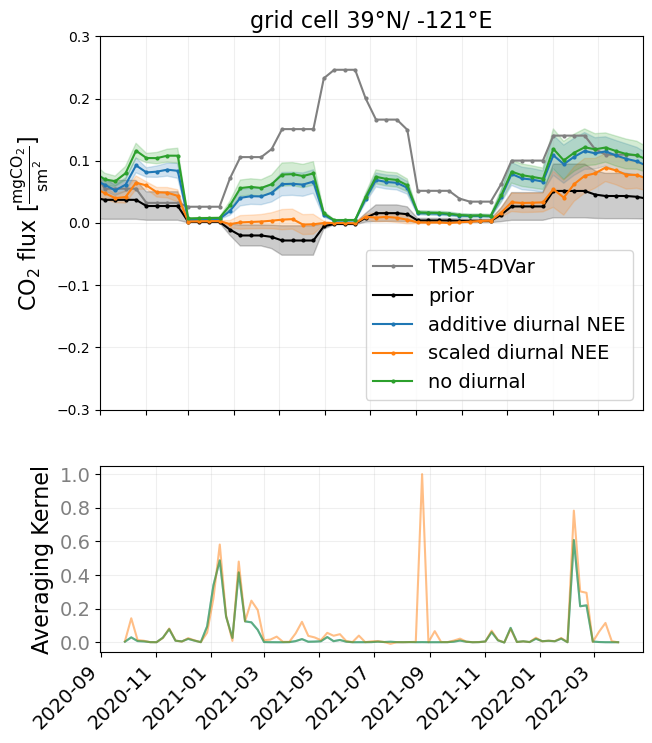

/tmp/ipykernel_2375853/4034925700.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


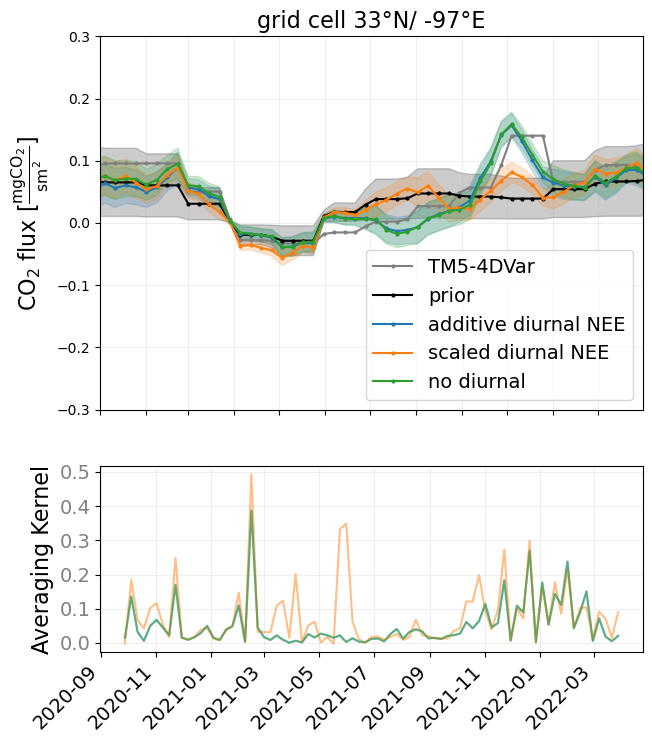

/tmp/ipykernel_2375853/4034925700.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


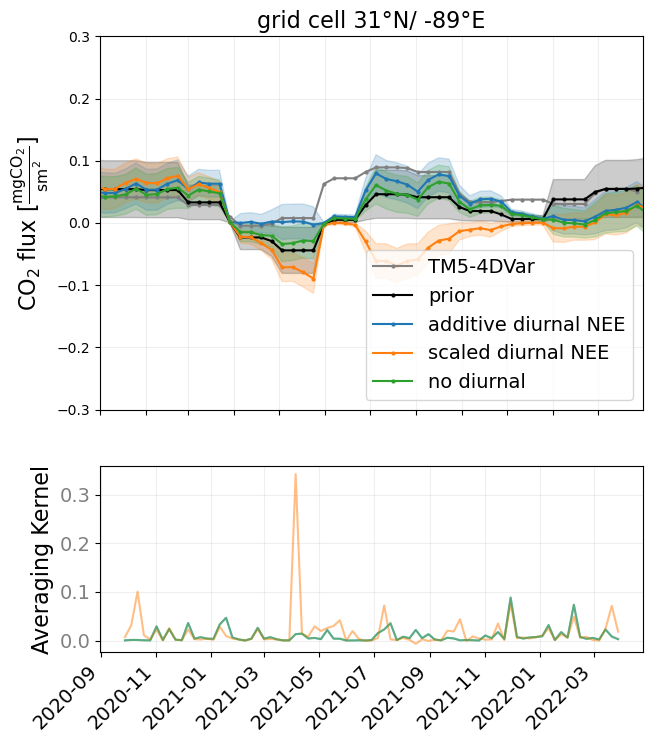

In [15]:

default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label=['additive diurnal NEE','scaled diurnal NEE','no diurnal' ]                           # ['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.','NEE scaled', 'no diurnal']
datasets= [nee_amplitude, scaled,no_diurnal ]   
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

min,max=-0.3,0.3
lat_lon=[(39,-123),(39,-121),(33,-97),(31,-89)]

# min,max=-0.6,0.3
# lat_lon=[(41,-97),(43,-95)]
datasets= [nee_amplitude, scaled,no_diurnal ]                                  # [nee_amplitude,nee2_amplitude,nee05_amplitude,scaled, no_diurnal]
for lat,lon in lat_lon:
    fig,axs=plt.subplots(2,1,figsize=(7,8),gridspec_kw={'height_ratios': [2, 1]})
    temp3=TM54DVar_posterior_flux.sel(latitude=lat,longitude=lon)
    temp3['total_flux']=temp3.total_flux*1e6
    axs[0].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar')
    k=0
    for data in datasets:
        temp=data.fluxes.sel(latitude=lat,longitude=lon)
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
        if k==0:
            axs[0].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
            axs[0].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2) 
        axs[0].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{label[k]}')
        axs[0].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
        axs[1].plot(temp.time, temp.TM5_averaging_kernel_diag, color=default_colors[k], alpha=0.5)
        k+=1

    
    axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
    axs[0].legend(fontsize=14)

    axs[0].set_xlim(analysis_start_date,analysis_end_date)
    axs[0].set_ylim(min,max)

    axs[0].tick_params(axis='x',labelbottom=False)
    axs[1].tick_params(axis='x', labelrotation=45,labelsize =14)
    plt.yticks(fontsize=14)
    axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')

    axs[0].grid(visible=True, which='major', axis='both', alpha=0.2)
    axs[1].grid(visible=True, which='major', axis='both', alpha=0.2)

    color = 'tab:blue'
    axs[1].set_ylabel('Averaging Kernel',fontsize=16)  # we already handled the x-label with ax1
    axs[1].tick_params(axis='y', labelcolor='gray')
    #axs[1].set_ylim(0,0.5)


    axs[0].set_title(f"grid cell {lat}°N/ {lon}°E",fontsize=16)
    plt.savefig(f'{savefig}/diurnal_setup_girdbox_{lat}lat_{lon}lon.pdf',bbox_inches='tight')#,transparent=True)
    plt.show()






In [17]:
nee_amplitude.fluxes

<xarray.Dataset> Size: 22MB
Dimensions:                    (time: 79, latitude: 22, longitude: 36,
                                meas_num: 15628)
Coordinates:
  * time                       (time) datetime64[ns] 632B 2020-09-28 ... 2022...
  * latitude                   (latitude) float32 88B 13.0 15.0 ... 53.0 55.0
  * longitude                  (longitude) float32 144B -133.0 -131.0 ... -63.0
  * meas_num                   (meas_num) int64 125kB 0 1 2 ... 15626 15627
    height                     float32 4B 30.0
Data variables:
    TM5_prior_flux             (time, latitude, longitude) float64 501kB -3.0...
    prior_uncertainty          (time, latitude, longitude) float64 501kB 2.58...
    TM5_posterior_flux         (time, latitude, longitude) float64 501kB -3.0...
    TM5_posterior_std          (time, latitude, longitude) float64 501kB 2.58...
    TM5_averaging_kernel_diag  (time, latitude, longitude) float64 501kB 3.34...
    meas                       (meas_num, time) float64 10MB -1.141 ... 3.16
    meas_cov                   (meas_num, time) float64 10MB 3.464 3.464 ... 3.0

In [19]:
diff=(nee_amplitude.fluxes.TM5_posterior_flux-scaled.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('difference additive diurnal - scaled diurnal')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
diff=np.abs(nee_amplitude.fluxes.TM5_posterior_flux-scaled.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('absolute difference')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=np.abs((nee_amplitude.fluxes.TM5_posterior_flux-scaled.fluxes.TM5_posterior_flux)/nee_amplitude.fluxes.TM5_posterior_std)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference additive diurnal - scaled diurnal
sum: 5.13872600916808e-05
max: 3.707122927311657e-07
min: -4.254688075340973e-07
mean: 1.6593664457401447e-09
absolute difference
sum: 0.00025191935719026887
max: 4.254688075340973e-07
min: 3.168074317916505e-15
mean: 8.134828119034774e-09
per standard deviation
max: 10.785449012318526
min: 1.6995132448422546e-05
mean: 0.6372512271194241


In [25]:
diff=(no_diurnal.fluxes.TM5_posterior_flux-nee_amplitude.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('difference no diurnal  - additive diurnal')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
diff=np.abs(no_diurnal.fluxes.TM5_posterior_flux-nee_amplitude.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('absolute difference')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=np.abs((no_diurnal.fluxes.TM5_posterior_flux-nee_amplitude.fluxes.TM5_posterior_flux)/nee_amplitude.fluxes.TM5_posterior_std)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference no diurnal  - additive diurnal
sum: -6.410796786794784e-05
max: 1.4145292361185637e-07
min: -1.4057500260866235e-07
mean: -2.070135877936833e-09
absolute difference
sum: 0.00011612458610292062
max: 1.4145292361185637e-07
min: 1.0397878762294924e-15
mean: 3.749825177696997e-09
per standard deviation
max: 6.768763001097413
min: 1.21529819133873e-05
mean: 0.2967519280218055


In [23]:
diff=(no_diurnal.fluxes.TM5_posterior_flux-scaled.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('difference no diurnal - scaled diurnal')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
diff=np.abs(no_diurnal.fluxes.TM5_posterior_flux-scaled.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('absolute difference')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=np.abs((no_diurnal.fluxes.TM5_posterior_flux-scaled.fluxes.TM5_posterior_flux)/nee_amplitude.fluxes.TM5_posterior_std)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference no diurnal - scaled diurnal
sum: -1.2720707776267032e-05
max: 3.749556087913322e-07
min: -3.905686959436097e-07
mean: -4.1076943219668794e-10
absolute difference
sum: 0.00026051549596183693
max: 3.905686959436097e-07
min: 2.5643443540549275e-15
mean: 8.41240945368887e-09
per standard deviation
max: 8.417367412464793
min: 1.9411569464187653e-05
mean: 0.664749425853821


# diurnal amplitude

/tmp/ipykernel_2148876/2137125894.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_2148876/2137125894.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_2148876/2137125894.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


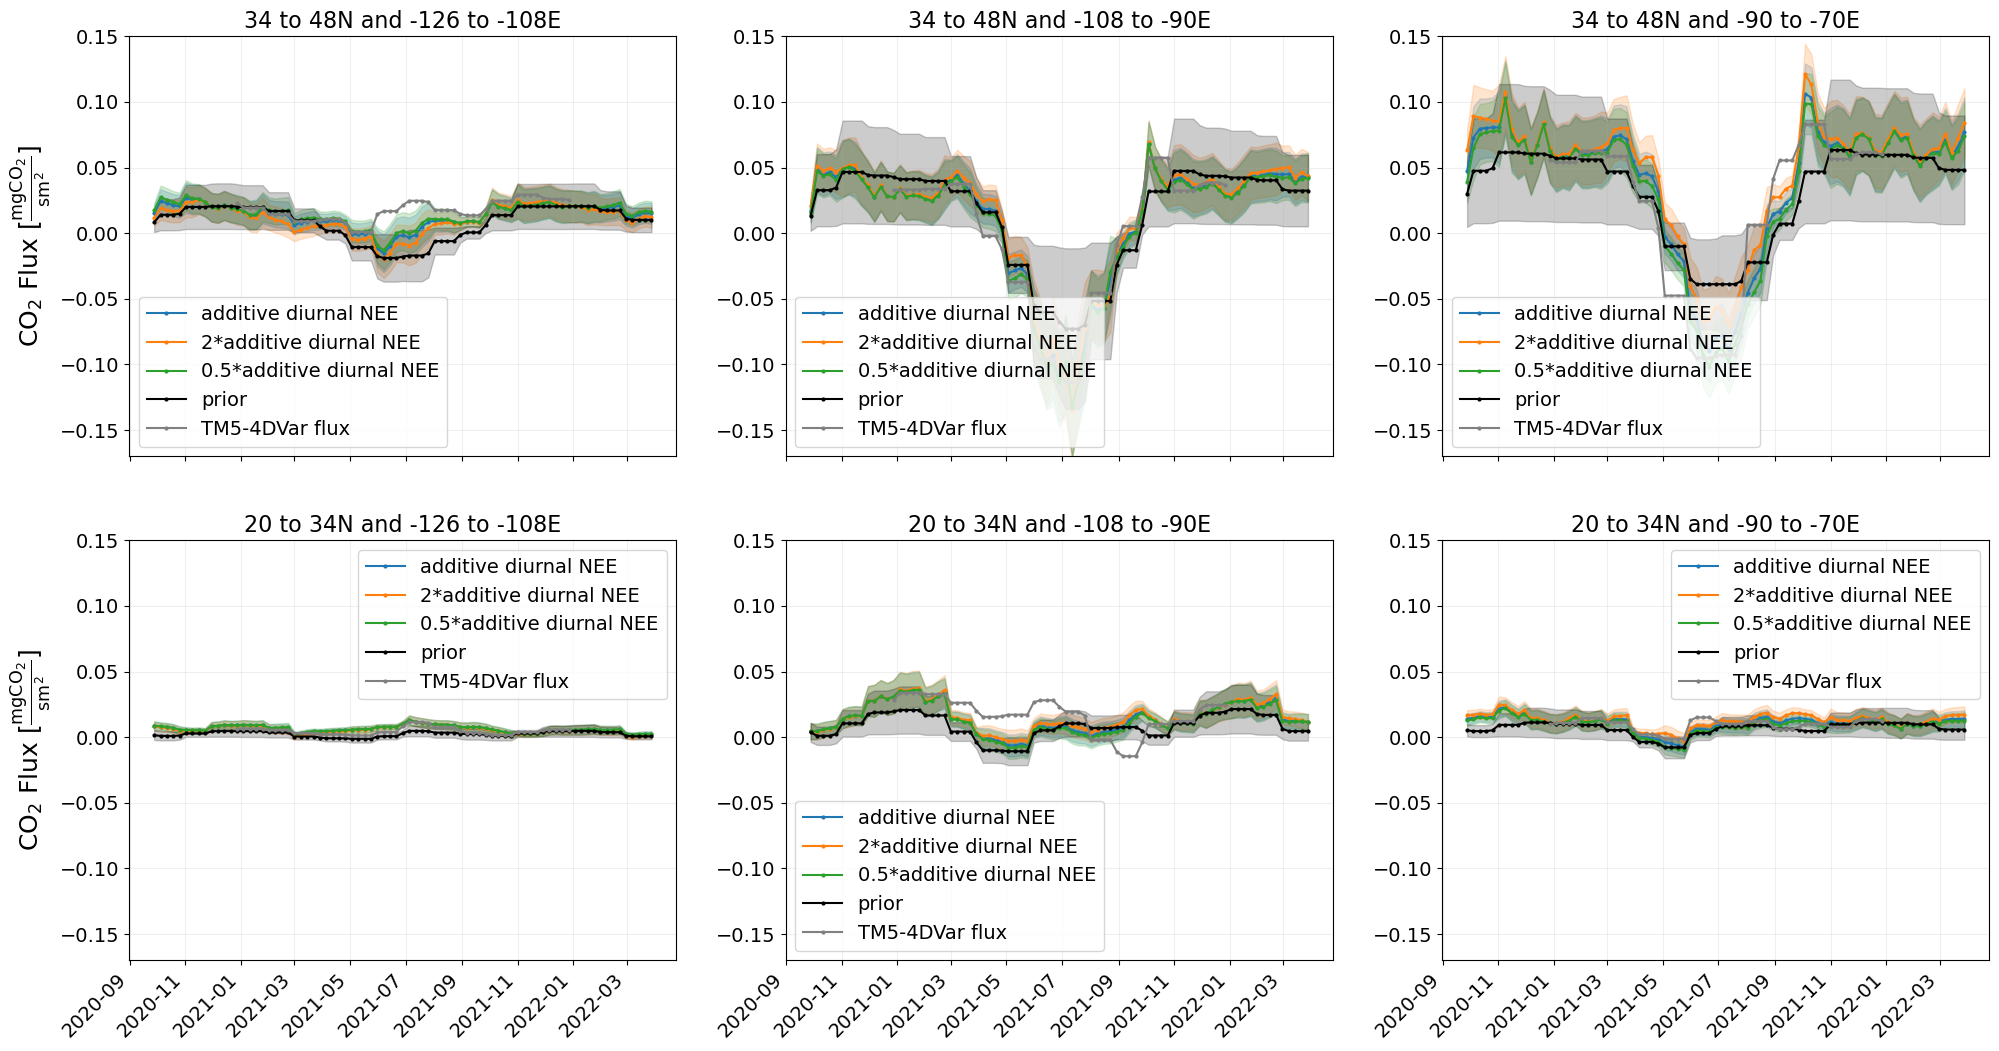

In [18]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['additive diurnal NEE','2*additive diurnal NEE','0.5*additive diurnal NEE' ]                           # ['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.','NEE scaled', 'no diurnal']
datasets= [nee_amplitude,nee2_amplitude,nee05_amplitude ]                                  # [nee_amplitude,nee2_amplitude,nee05_amplitude,scaled, no_diurnal]
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        k=0
        for k,data in enumerate(datasets):
            temp=data.fluxes
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{label_set[k]}')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6

        axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2)  
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')

        #axs[i,j].tight_layout()
        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(-0.17,0.15)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.savefig(f'{savefig}/regional_fluxes_diff_diurnal_amplitude.pdf',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

In [17]:
prior_path=f'{nee_amplitude.path}/{period}_{BG_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.']

colors=['black','grey']
marker=['x','x']
k=0
for k,dataset in enumerate([nee_amplitude,nee2_amplitude,nee05_amplitude]):
    datasets_dir.append(f'{dataset.path}/{dataset.period}_{dataset.BG_ds}_bg.nc')
    labels.append(label_set[k])
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')
print(datasets_dir)
print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'different diurnal amplitude', analysis_start_date, analysis_end_date,savefig+'/different_diurnal_amplitude_'+'2x2.png')


['inversions_new/TM5_correlations//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', '/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc', 'inversions_new/TM5_correlations//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', 'inversions_new/TM5_diurnal/TM5_2nee/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', 'inversions_new/TM5_diurnal/TM5_05nee/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc']
['TM5_prior_flux', 'total_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux']
['prior_uncertainty', False, 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_poste

<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\o'
<>:44: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\o'
<>:18: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\o'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\o'
<>:44: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_758705/1921975825.py:18: SyntaxWarning: invalid escape sequence '\o'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_758705/1921975825.py:18: SyntaxWarning: invalid escape sequence '\s'
  print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )
/tmp/ipykernel_758705/1921975825.py:31: SyntaxWarning: invalid escape sequence '\o'
  print(f'GOSA

NEE ampl.
insitu: , $\overline{d}=0.07, \sigma=2.82$
GOSAT: , $\overline{d}=0.05, \sigma=2.53$
TCCON: , $\overline{d}=-0.7, \sigma=1.89$
NEE 2*ampl.
insitu: , $\overline{d}=-0.31, \sigma=2.82$
GOSAT: , $\overline{d}=-0.03, \sigma=2.53$
TCCON: , $\overline{d}=-0.73, \sigma=1.89$
NEE 0.5*ampl.
insitu: , $\overline{d}=-0.17, \sigma=2.77$
GOSAT: , $\overline{d}=0.06, \sigma=2.53$
TCCON: , $\overline{d}=-0.71, \sigma=1.87$
NEE scaled
insitu: , $\overline{d}=-0.29, \sigma=2.41$
GOSAT: , $\overline{d}=-0.05, \sigma=2.51$
TCCON: , $\overline{d}=-0.74, \sigma=1.91$
no diurnal
insitu: , $\overline{d}=-0.13, \sigma=2.84$
GOSAT: , $\overline{d}=0.09, \sigma=2.54$
TCCON: , $\overline{d}=-0.71, \sigma=1.87$


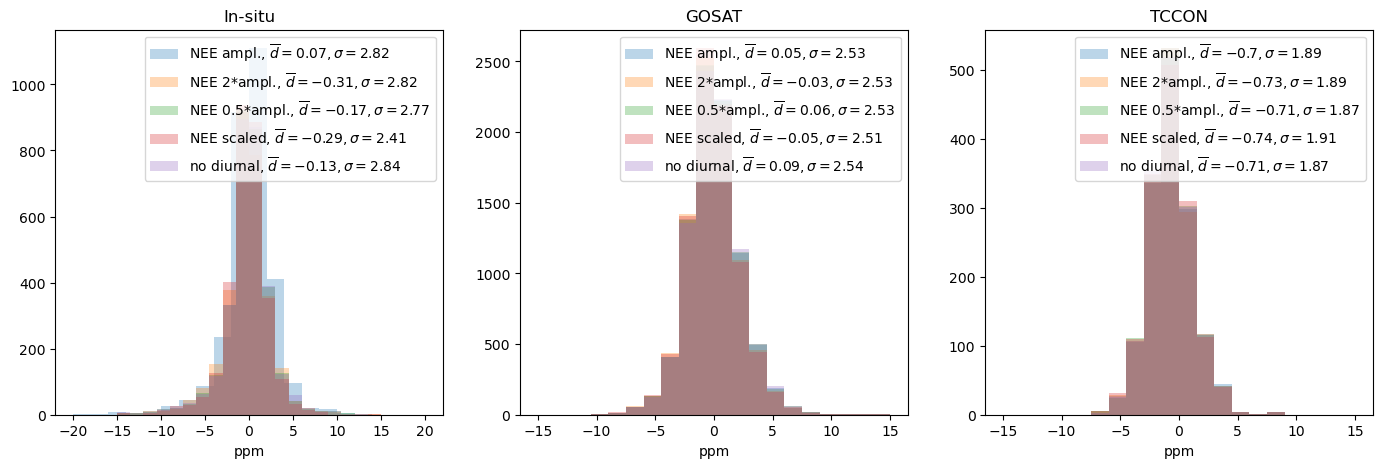

In [21]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
label_set=['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.','NEE scaled','no diurnal']
for k,data in enumerate([nee_amplitude,nee2_amplitude,nee05_amplitude,scaled,no_diurnal]):
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    print(label_set[k])
    temp=data.insitu
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'insitu: , $\overline{{d}}={d0}, \sigma={d_std}$' )

    axs[0].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[0].legend()
    axs[0].set_xlabel('ppm')
    axs[0].set_title(title[0])

    max_min=(-15,15)
    temp=data.gosat
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'GOSAT: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[1].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[1].legend()
    axs[1].set_xlabel('ppm')
    axs[1].set_title(title[1])

    
    max_min=(-15,15)
    temp=data.tccon
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=label=fr'{label_set[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    print(f'TCCON: , $\overline{{d}}={d0}, \sigma={d_std}$' )
    axs[2].hist(temp.posterior_diff,alpha=0.3, bins=nbins, range=max_min, label=label)
    axs[2].legend()
    axs[2].set_xlabel('ppm')
    axs[2].set_title(title[2])

plt.savefig(f'{savefig}/histogramm_diff_diurnal.png')

In [11]:
data

In [38]:
nee_amplitude.path

'inversions_new/TM5_correlations//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err/'

In [45]:
prior_path=f'{nee_amplitude.path}/{period}_{BG_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.','NEE scaled', 'no diurnal']

colors=['black','grey']
marker=['x','x']
k=0
for k,dataset in enumerate([nee_amplitude,nee2_amplitude,nee05_amplitude,scaled,no_diurnal]):
    datasets_dir.append(f'{dataset.path}/{dataset.period}_{dataset.BG_ds}_bg.nc')
    labels.append(label_set[k])
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')
print(datasets_dir)
print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'different diurnal', analysis_start_date, analysis_end_date,savefig+'/different_diurnal_'+'2x2.png')


['inversions_new/TM5_correlations//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', '/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc', 'inversions_new/TM5_correlations//2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', 'inversions_new/TM5_diurnal/TM5_2nee/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', 'inversions_new/TM5_diurnal/TM5_05nee/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc', 'inversions_new/TM5_diurnal/scaled/2x2/with_correlation/footprint_spec001_mr_scaled/2ppm_gosat_meas_err/3ppm_insitu_meas_err//20201001-20220331_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc

: 

<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2148876/3900437915.py:26: SyntaxWarning: invalid escape sequence '\m'
  axs.set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=14)


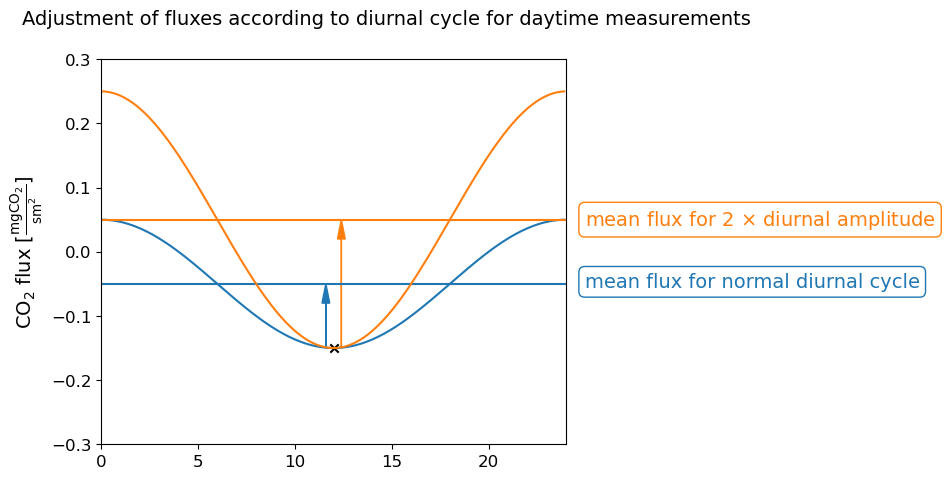

In [19]:
color_normal=default_colors[0]
color_2nee=default_colors[1]
fig,axs=plt.subplots(figsize=(6,5))
fig.suptitle('Adjustment of fluxes according to diurnal cycle for daytime measurements', x=0.6, fontsize=14)
x=np.arange(0,24,0.1)
plt.plot(x,0.1*np.cos(x*2*np.pi/24)-0.05,c=color_normal)
axs.hlines(-.05,0,24,color=color_normal)
plt.arrow(12-0.4,0.1*np.cos(12*2*np.pi/24)-0.05, 0,0.1,color=color_normal, length_includes_head=True, head_length=0.03 ,head_width=0.4)
textstr = 'mean flux for normal diurnal cycle'
props = dict(boxstyle='round',edgecolor=color_normal, facecolor='white', alpha=1)

axs.text(1.04, 0.25/0.6+0.03, textstr, transform=axs.transAxes, fontsize=14, color=color_normal,
        verticalalignment='top', bbox=props)

plt.plot(x,0.2*np.cos(x*2*np.pi/24)+0.05,c=color_2nee)
axs.hlines(0.05,0,24,color=color_2nee)
plt.arrow(12+0.4,0.2*np.cos(12*2*np.pi/24)+0.05, 0,0.2,color=color_2nee, length_includes_head=True, head_length=0.03 ,head_width=0.4)
textstr = 'mean flux for 2 $\\times$ diurnal amplitude'
props = dict(boxstyle='round',edgecolor=color_2nee, facecolor='white', alpha=1)

axs.text(1.04, 0.35/0.6+0.03, textstr, transform=axs.transAxes, fontsize=14, color=color_2nee,
        verticalalignment='top', bbox=props)

axs.scatter(12,0.1*np.cos(12*2*np.pi/24)-0.05, c='black',marker='x')

axs.set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.ylim(-0.3,0.3)
plt.xlim(0,24)
plt.savefig(savefig+'/schematic_flux_adjustment_daytime_measurements.pdf', bbox_inches='tight')


<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2148876/1936684292.py:26: SyntaxWarning: invalid escape sequence '\m'
  axs.set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=14)


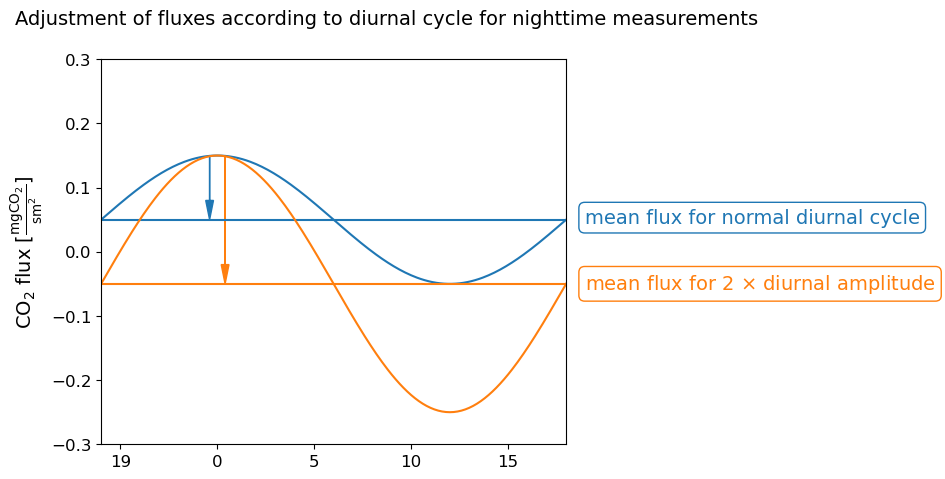

In [20]:
color_normal=default_colors[0]
color_2nee=default_colors[1]
fig,axs=plt.subplots(figsize=(6,5))
fig.suptitle('Adjustment of fluxes according to diurnal cycle for nighttime measurements', x=0.6, fontsize=14)
x=np.arange(-6,24,0.1)
plt.plot(x,0.1*np.cos(x*2*np.pi/24)+0.05,c=color_normal)
axs.hlines(+0.05,-6,24,color=color_normal)
plt.arrow(0-0.4,0.1*np.cos(0*2*np.pi/24)+0.05, 0,-0.1,color=color_normal, length_includes_head=True, head_length=0.03 ,head_width=0.4)
textstr = 'mean flux for normal diurnal cycle'
props = dict(boxstyle='round',edgecolor=color_normal, facecolor='white', alpha=1)

axs.text(1.04, 0.35/0.6+0.03, textstr, transform=axs.transAxes, fontsize=14, color=color_normal,
        verticalalignment='top', bbox=props)

plt.plot(x,0.2*np.cos(x*2*np.pi/24)-0.05,c=color_2nee)
axs.hlines(-0.05,-6,24,color=color_2nee)
plt.arrow(0+0.4,0.2*np.cos(0*2*np.pi/24)-0.05, 0,-0.2,color=color_2nee, length_includes_head=True, head_length=0.03 ,head_width=0.4)
textstr = 'mean flux for 2 $\\times$ diurnal amplitude'
props = dict(boxstyle='round',edgecolor=color_2nee, facecolor='white', alpha=1)

axs.text(1.04, 0.25/0.6+0.03, textstr, transform=axs.transAxes, fontsize=14, color=color_2nee,
        verticalalignment='top', bbox=props)

axs.scatter(24,0.1*np.cos(24*2*np.pi/24)-0.05, c='black',marker='x')

axs.set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=14)


plt.ylim(-0.3,0.3)
plt.xlim(-6,18)
plt.xticks(fontsize=12,ticks=[-5,0,5,10,15],labels=[19,0,5,10,15])
plt.yticks(fontsize=12)
plt.savefig(savefig+'/schematic_flux_adjustment_nighttime_measurements.pdf', bbox_inches='tight')



In [16]:
diff=(nee2_amplitude.fluxes.TM5_posterior_flux-nee_amplitude.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('difference doubled amplitude - normal amplitude')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
diff=np.abs(nee2_amplitude.fluxes.TM5_posterior_flux-nee_amplitude.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('absolute difference')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=np.abs((nee2_amplitude.fluxes.TM5_posterior_flux-nee_amplitude.fluxes.TM5_posterior_flux)/nee_amplitude.fluxes.TM5_posterior_std)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference doubled amplitude - normal amplitude
sum: 6.410796786794806e-05
max: 1.4057500260866216e-07
min: -1.4145292361185658e-07
mean: 2.07013587793684e-09
absolute difference
sum: 0.00011612458610292078
max: 1.4145292361185658e-07
min: 1.0397878761067078e-15
mean: 3.749825177697003e-09
per standard deviation
max: 6.768763001097382
min: 1.2152981909334375e-05
mean: 0.29675192802180606


In [17]:
diff=(nee05_amplitude.fluxes.TM5_posterior_flux-nee_amplitude.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('difference halved amplitude - normal amplitude')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
diff=np.abs(nee05_amplitude.fluxes.TM5_posterior_flux-nee_amplitude.fluxes.TM5_posterior_flux)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print('absolute difference')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=np.abs((nee05_amplitude.fluxes.TM5_posterior_flux-nee_amplitude.fluxes.TM5_posterior_flux)/nee_amplitude.fluxes.TM5_posterior_std)
diff=diff.where(((diff.latitude>= analy_region_lat[0]) &(diff.latitude<analy_region_lat[1])),drop=True)
diff=diff.where(((diff.longitude>= analy_region_lon[0]) &(diff.longitude<analy_region_lon[1])),drop=True)
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference halved amplitude - normal amplitude
sum: -3.2053983933974105e-05
max: 7.072646180592869e-08
min: -7.028750130433154e-08
mean: -1.0350679389684224e-09
absolute difference
sum: 5.8062293051460405e-05
max: 7.072646180592869e-08
min: 5.198939380678942e-16
mean: 1.874912588848502e-09
per standard deviation
max: 3.3843815005487112
min: 6.07649095669365e-06
mean: 0.14837596401090278
